# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 requires** either (branching) a Gast/pSom **hub** diverging into two arms with
Crest high at the tips, or (non-branching) a **shared** Gast/pSom gradient with Crest
as an **inverse/terminal** gradient at the far end. **Neither pattern is present in
Hwang 2022.** The manifold resolves into **three mutually-exclusive territories** — all
three modules are pairwise anti-correlated (Gast/pSom -0.33, pSom/Crest -0.39,
Gast/Crest -0.30) and no two co-occur anywhere (all pairwise joint-high enrichments are
*depleted*, 0.35-0.45), so there is **no convergence hub**. And Crest is **not
terminal**: its high decile sits at mid-pseudotime (0.50), not at the trajectory end.
This is the three-territory triangle with no terminal readout (the Peng 2019 same-PDAC
signature), the opposite of Steele 2020's GO (Crest terminal at pt 0.87). **Gate 2 =
NO-GO**; the embryonic pattern does not reproduce. With no bifurcation, **Gate 3 = NA**.

Per §6, a Gate-2 NO-GO stops the gate chain here: the branching-only correlation/modules
notebooks are **not** produced, and the unconditional EMT-TF expression step follows as
`04_expression`. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 64399 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present


### Gate 2 — module geography on the manifold (biology-led)
Three quantitative tests, read from the graph-smoothed scores (geography), decide the
gate — before any figure. (1) **Hub test:** for each module pair, the joint-high
enrichment (observed / expected co-occurrence of both upper quartiles); >1 means the
modules co-occur (a hub), <1 means mutually-exclusive territories. (2) **Terminal
test:** mean normalized pseudotime of each module's high decile; a terminal Crest
readout sits near 1. (3) **Spatial correlations.** All three point the same way: no
hub, Crest not terminal, three exclusive territories.

In [6]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('(3) smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'    {a} vs {b}: r = {r:+.2f}')
print('\n(1) HUB test - pairwise joint-high enrichment (obs/exp; >1 hub, <1 exclusive territory):')
for a,b in [('Gast_sm','pSom_sm'),('pSom_sm','Crest_sm'),('Gast_sm','Crest_sm')]:
    aq = adata.obs[a]>=adata.obs[a].quantile(0.75); bq = adata.obs[b]>=adata.obs[b].quantile(0.75)
    obs=(aq&bq).mean(); exp=aq.mean()*bq.mean(); print(f'    {a} & {b}: enrich = {obs/exp:.2f}')
print('\n(2) TERMINAL test - mean normalized pseudotime of each module high-decile (~1 = terminal):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    rho,_ = spearmanr(t, adata.obs[m])
    print(f'    {m}: high-decile mean pt = {tn[hi.values].mean():.2f} | rho_vs_pt = {rho:+.3f}')
print('\nGate 2: no Gast/pSom hub (all pairs depleted) + Crest mid-axis not terminal')
print('        + three mutually-exclusive territories -> NO-GO (embryonic pattern absent)')
print('Gate 3: no bifurcation -> NA')

(3) smoothed spatial correlations (geography):
    Gast_sm vs pSom_sm: r = -0.33
    Crest_sm vs Gast_sm: r = -0.30
    Crest_sm vs pSom_sm: r = -0.39

(1) HUB test - pairwise joint-high enrichment (obs/exp; >1 hub, <1 exclusive territory):
    Gast_sm & pSom_sm: enrich = 0.35
    pSom_sm & Crest_sm: enrich = 0.45
    Gast_sm & Crest_sm: enrich = 0.38

(2) TERMINAL test - mean normalized pseudotime of each module high-decile (~1 = terminal):
    Gast_sm: high-decile mean pt = 0.11 | rho_vs_pt = -0.656
    pSom_sm: high-decile mean pt = 0.76 | rho_vs_pt = +0.114
    Crest_sm: high-decile mean pt = 0.50 | rho_vs_pt = +0.137

Gate 2: no Gast/pSom hub (all pairs depleted) + Crest mid-axis not terminal
        + three mutually-exclusive territories -> NO-GO (embryonic pattern absent)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right, `size=30`, plasma, **raw**
(not smoothed) score per cell so 10x dropout is visible (the geography above was read
from the smoothed scores; the deliverable shows the raw per-cell scores, per 04_test).
These panels make the three-territory triangle visible: each module lights a *different*
region with little overlap.

<cell 8>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 8>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 8>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


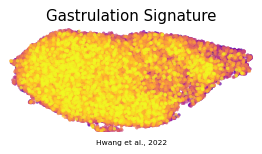

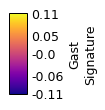

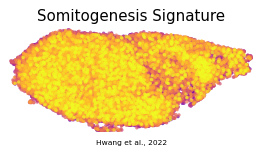

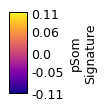

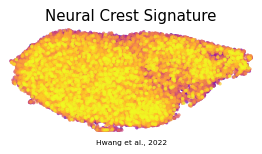

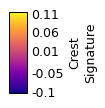

In [8]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m], vmax='p99', vmin='p1')
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(np.percentile(adata.obs[m],1)), float(np.percentile(adata.obs[m],99))
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [10]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (64399, 19457)
